In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), '../src'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
file_ids = [0]
plot_id = 0

neurons_max = 5
bhl_selection = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

dims = 2

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, file_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = markers[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	markers[i] = markers[i][mask]
	states[i] = states[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

# add shifted markers in time
for i in range(len(file_ids)):
	max_shift_seconds = 5
	max_shift = int(max_shift_seconds * sampling_rates[i])
	if max_shift > 0:
		markers_shifted = dict()
		for marker_label in markers[i].columns:
			for s in range(1, int(max_shift) + 1):
				shift_seconds = s / sampling_rates[i]
				markers_shifted[f'{marker_label}-{shift_seconds:.2f}s'] = np.pad(markers[i][marker_label].values[:-s], ((s, 0),))
		markers[i] = pd.concat([markers[i], pd.DataFrame(markers_shifted, index=markers[i].index)], axis=1)

In [6]:
plot_idx = file_ids.index(plot_id)

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

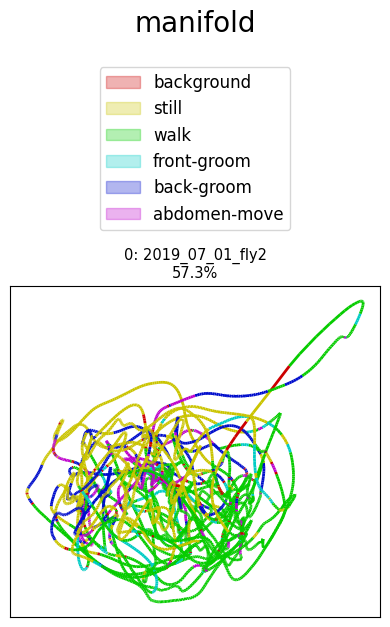

57.3%


In [8]:
plot_utils.plot_manifolds(
	[f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
	modes_manifold, states,
	vars_expl_mans, None,
	title='manifold', top_space=2.5,
						  save_path=None)

In [9]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

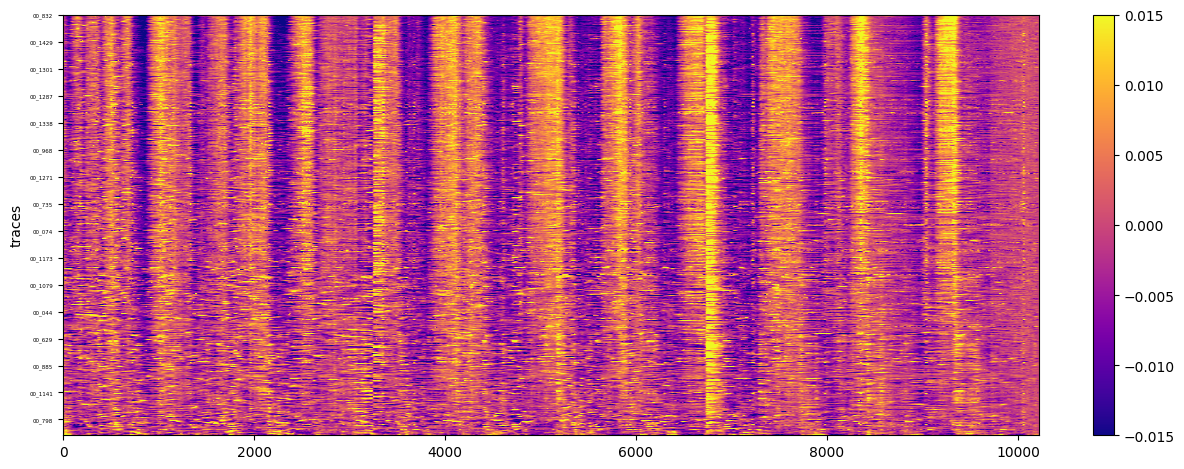

In [10]:
# plot
plot_utils.plot_heatmap_stack(
	traces_sorted[plot_idx],
	None,
	'neuronal traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

In [ ]:
# plot
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[plot_idx],
	None,
	'neuronal manifold traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

In [11]:
traces_residuals = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

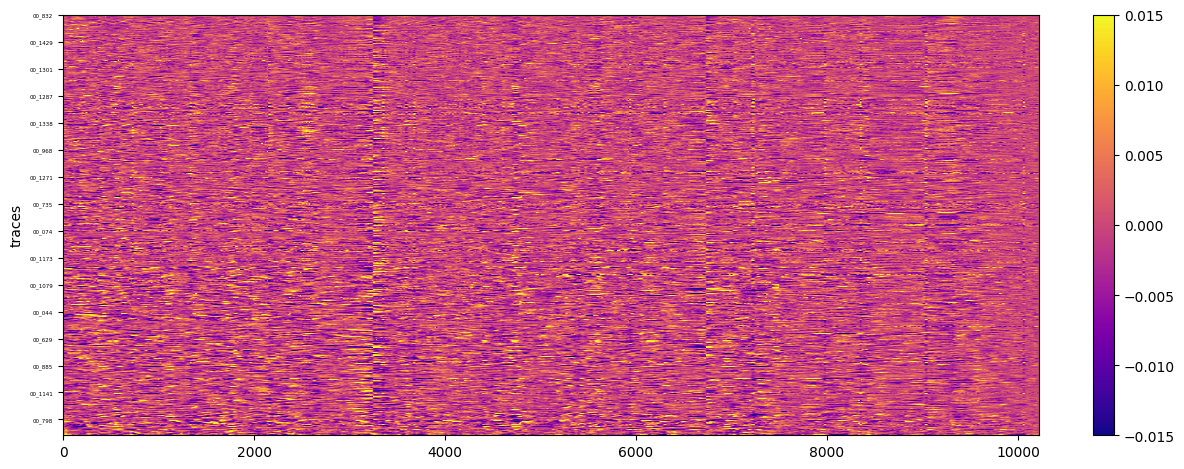

In [12]:
# plot
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[plot_idx],
	None,
	'neuronal residual traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

# regression

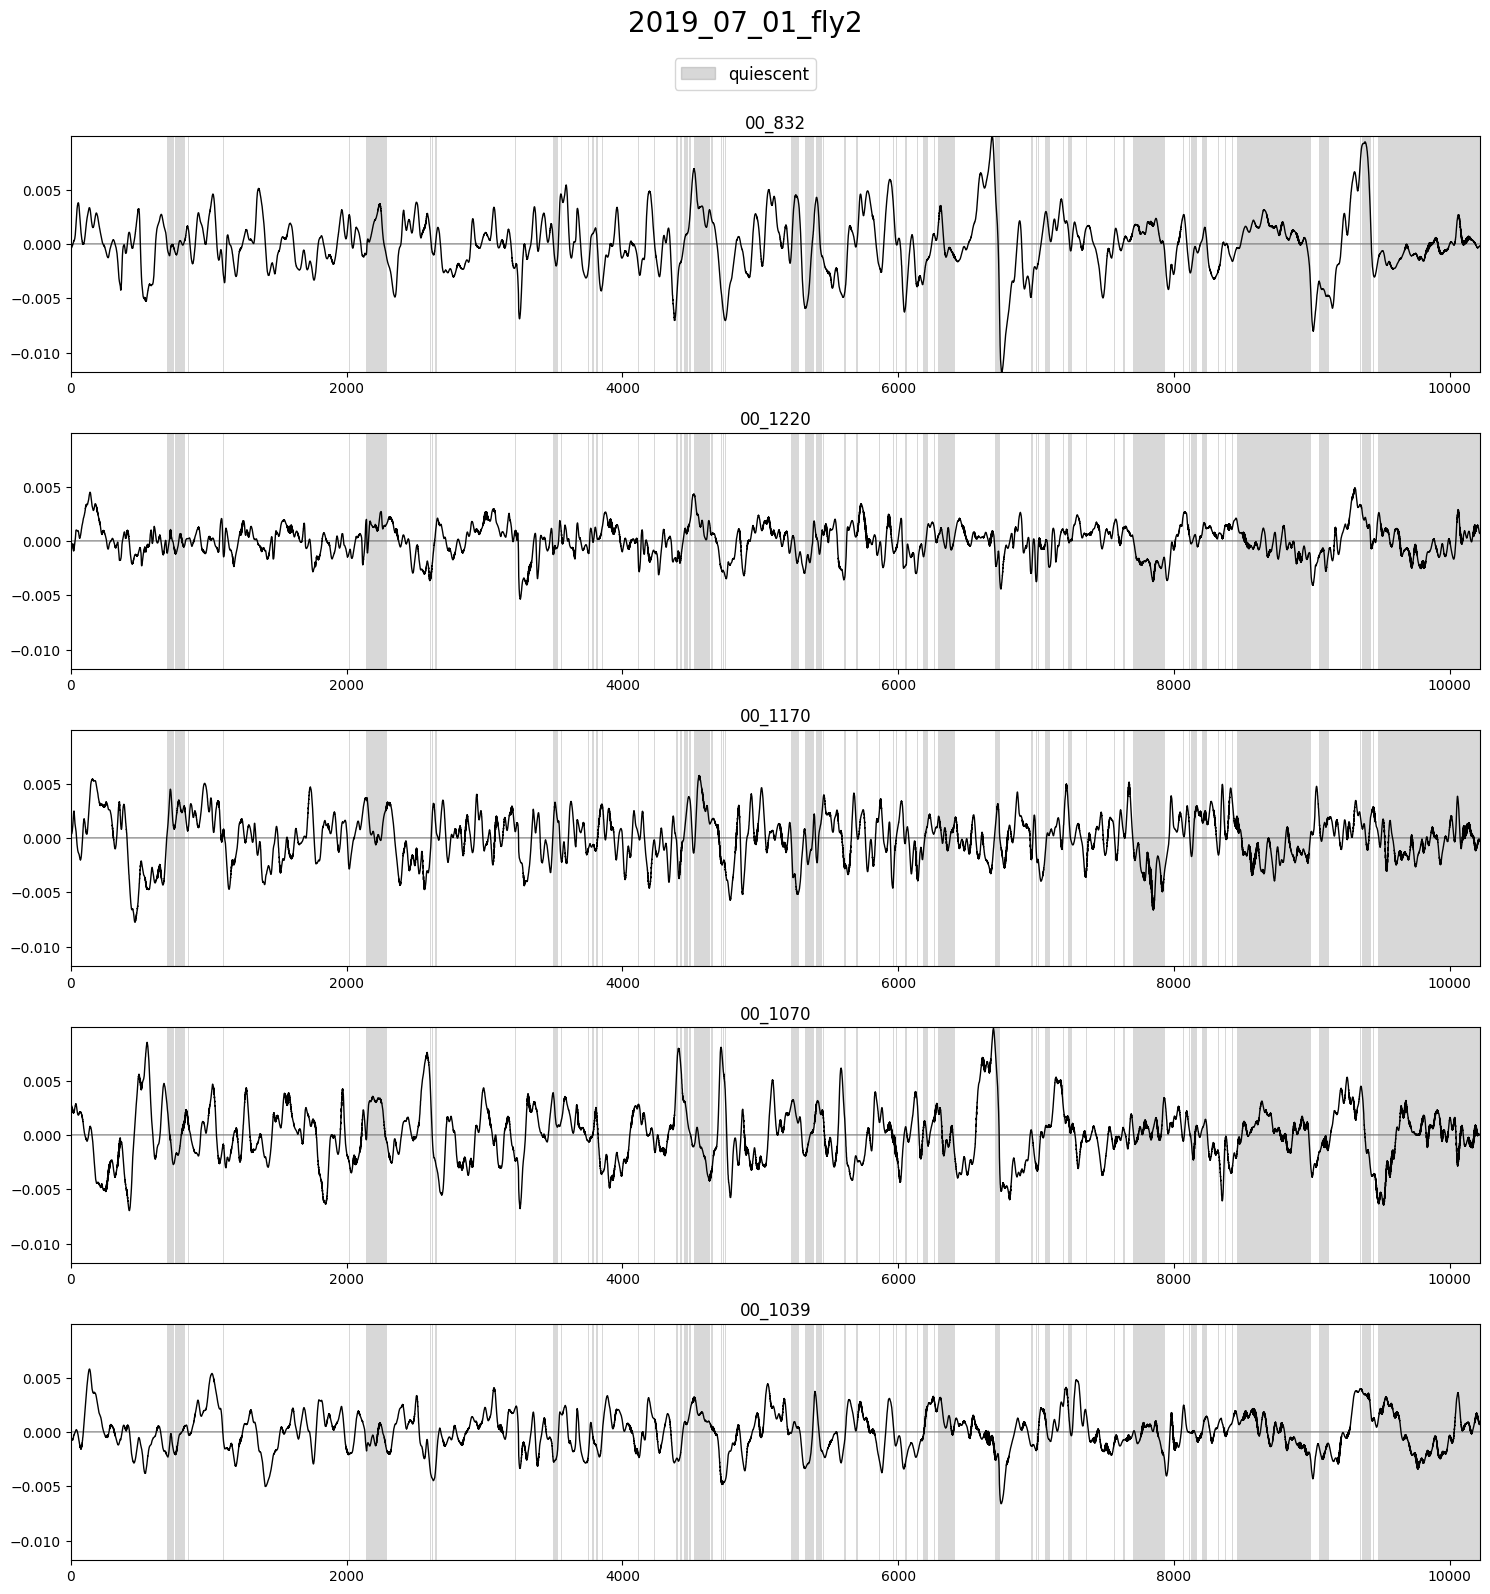

In [13]:
# max = 1000
max = traces_residuals[plot_idx].values.shape[0]

plot_utils.plot_traces(traces_residuals_sorted_by_manifold[plot_idx].iloc[:, :neurons_max],
					   states[plot_idx][['still']],
					   label='quiescent',
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

In [15]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]
markers_grad_zs = [
	pd.DataFrame(
		data=(marker_grad.values - marker_grad.values.mean(axis=0)) / np.where((marker_grad_std := np.std(marker_grad.values, axis=0)) == 0.0, 1.0, marker_grad_std),
		columns=marker_grad.columns)
	for marker_grad in markers_grad
]

In [14]:
def r2_score_oos(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2, axis=0)
	ss_tot = np.sum((y_eval - baseline) ** 2, axis=0)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

In [16]:
traces_residual_pred = list()
r2s = [pd.DataFrame(), pd.DataFrame()]

for i, markers_version in enumerate([markers_zs, markers_grad_zs]):
	marker = markers_version[plot_idx]
	trace = traces_residuals[plot_idx]

	scaler = StandardScaler()
	trace_zs = scaler.fit_transform(trace.values)

	X_train, X_test, Y_train, Y_test = train_test_split(
		marker.values, trace_zs, test_size=0.2, random_state=42
	)

	lr = LinearRegression()
	lr.fit(X_train, Y_train)

	Y_test_pred = lr.predict(X_test)

	r2 = r2_score_oos(Y_test, Y_test_pred, Y_train.mean(axis=0)).reshape(-1, 1).T
	r2s[i] = pd.DataFrame(data=r2, columns=trace.columns)

	r2_mean = np.mean(r2_score_oos(Y_test, Y_test_pred, Y_train.mean(axis=0)))
	mse = mean_squared_error(Y_test, Y_test_pred)

	traces_residual_pred.append(pd.DataFrame(data=scaler.inverse_transform(lr.predict(marker.values)), columns=trace.columns))

	print(i, "Mean R²:\t", r2_mean)
	print(i, "MSE:\t\t", mse)

0 Mean R²:	 0.03874874211574472
0 MSE:		 0.9587722164314653
1 Mean R²:	 -0.0036202811208507425
1 MSE:		 1.0010356693815106


In [17]:
r2_indices = [np.argsort(r2s[0].values.reshape(-1,))[::-1], np.argsort(r2s[1].values.reshape(-1,))[::-1]]
print(r2s[0].iloc[:, r2_indices[0][:5]])
print(r2s[1].iloc[:, r2_indices[1][:5]])

     00_568    00_521    00_907    00_471   00_656
0  0.149138  0.140172  0.136607  0.120807  0.11884
     00_916    00_120   00_1376    00_912   00_1303
0  0.000961  0.000656  0.000598  0.000455  0.000125


In [18]:
print(r2s[0].iloc[:, r2_indices[0]]['00_249'])

0    0.067502
Name: 00_249, dtype: float64


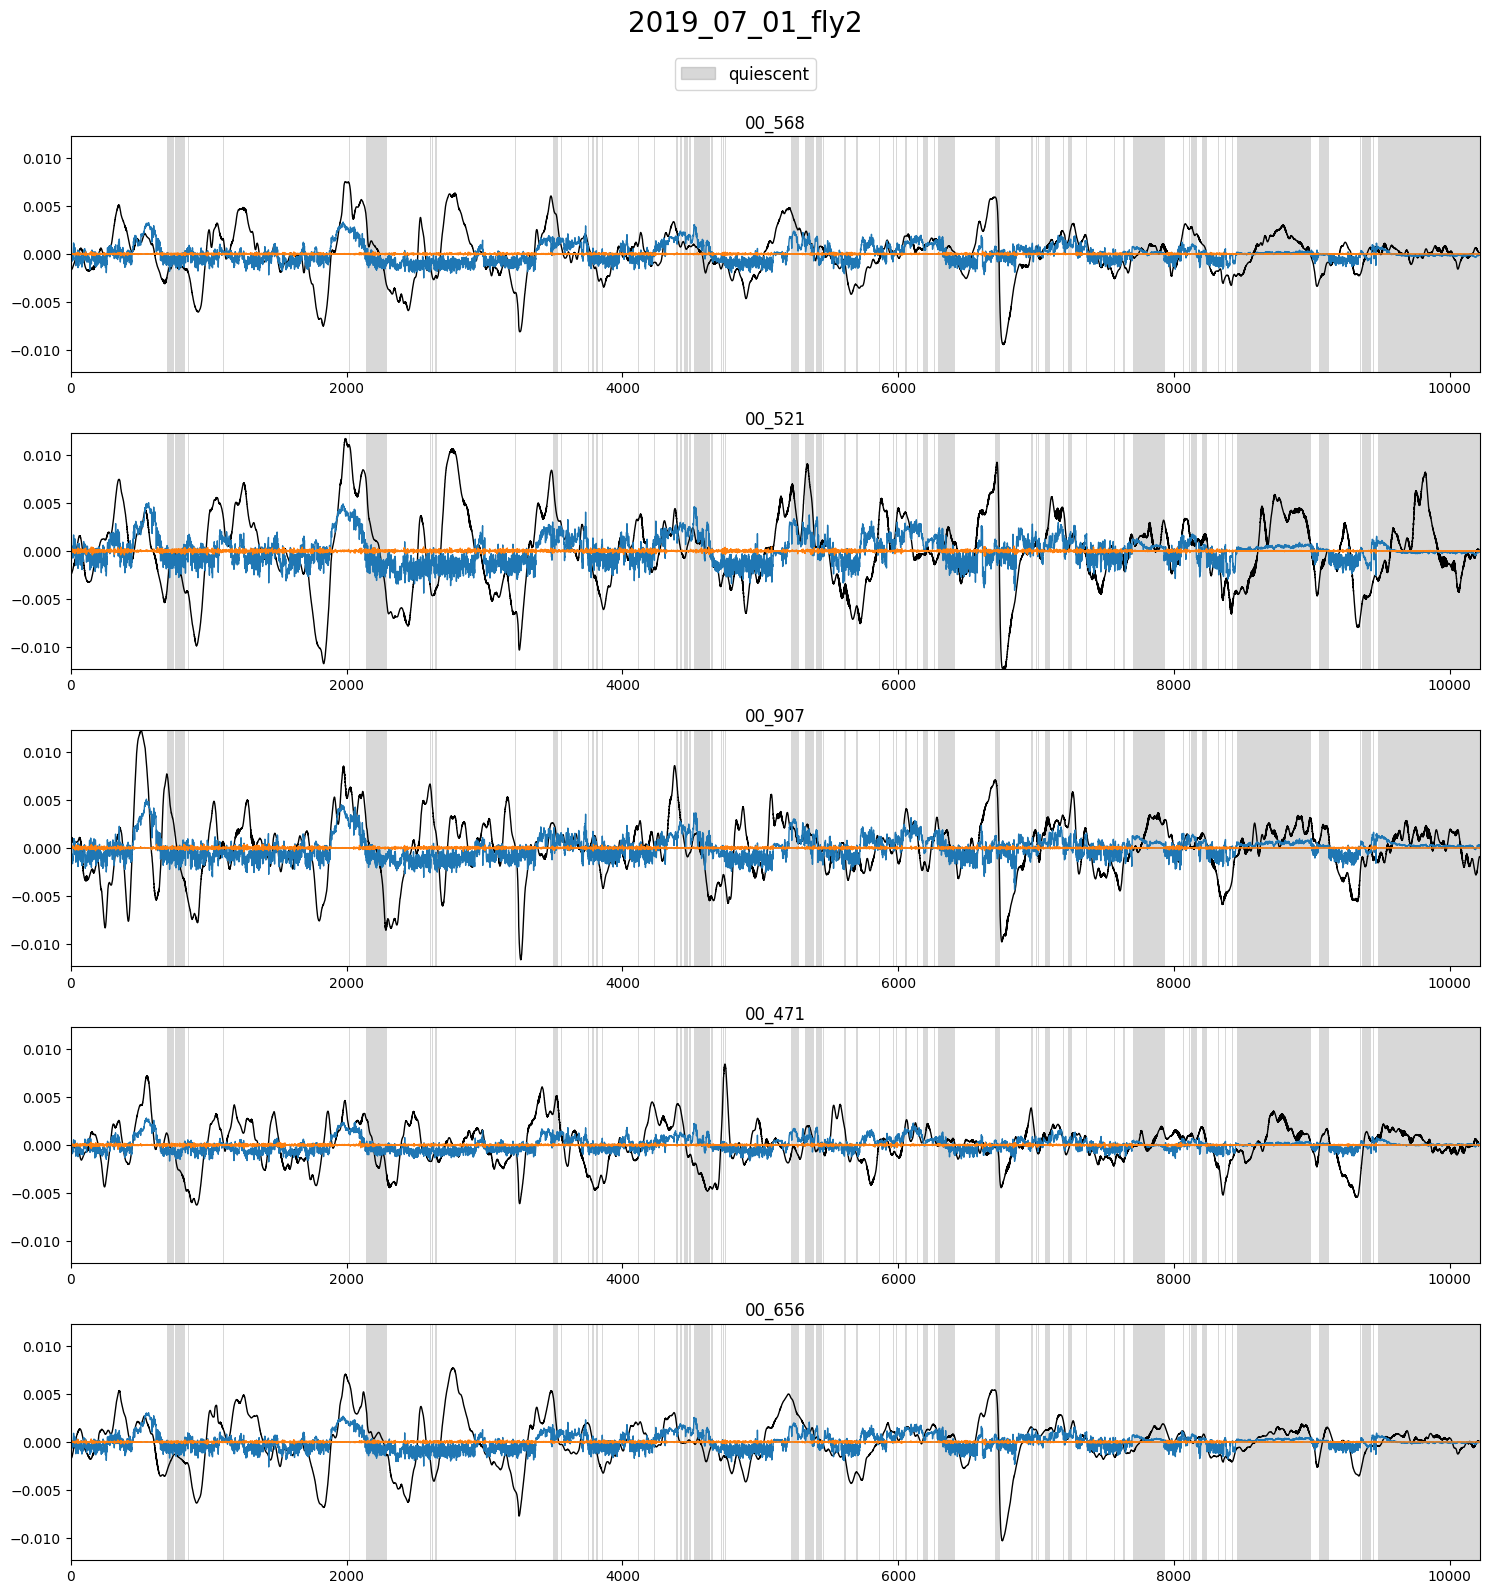

In [31]:
# max = 1000
max = traces_residuals[plot_idx].values.shape[0]

plot_utils.plot_traces([traces_residuals[plot_idx].iloc[:max, r2_indices[0][:5]],
					    traces_residual_pred[0].iloc[:max, r2_indices[0][:5]],
					    traces_residual_pred[1].iloc[:max, r2_indices[0][:5]]],
					   states[plot_idx].loc[:max, ['still']],
					   label='quiescent',
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

# CCA comparison

In [21]:
n_ccv = markers_zs[plot_idx].values.shape[1]

modes_concrete, modes_concrete_b = list(), list()
recos_concrete, recos_concrete_b = list(), list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data
for i, markers_version in enumerate([markers, markers_grad]):
	marker = markers_version[plot_idx]
	trace = traces[plot_idx]
	trace_residual = traces_residuals[plot_idx]

	cca = CCA(n_components=n_ccv, scale=True)

	trace_residual_reduced, marker_reduced = cca.fit_transform(trace_residual.values, marker.values)
	trace_residual_reconstructed, marker_reconstructed = cca.inverse_transform(trace_residual_reduced, marker_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	modes_concrete_b.append(pd.DataFrame(data=marker_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)]))
	recos_concrete_b.append(pd.DataFrame(data=marker_reconstructed, columns=marker.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace.values)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual.values)
	vars_expl_con.append([var_ratio])
	vars_expl_con_rs.append([var_ratio_rs])

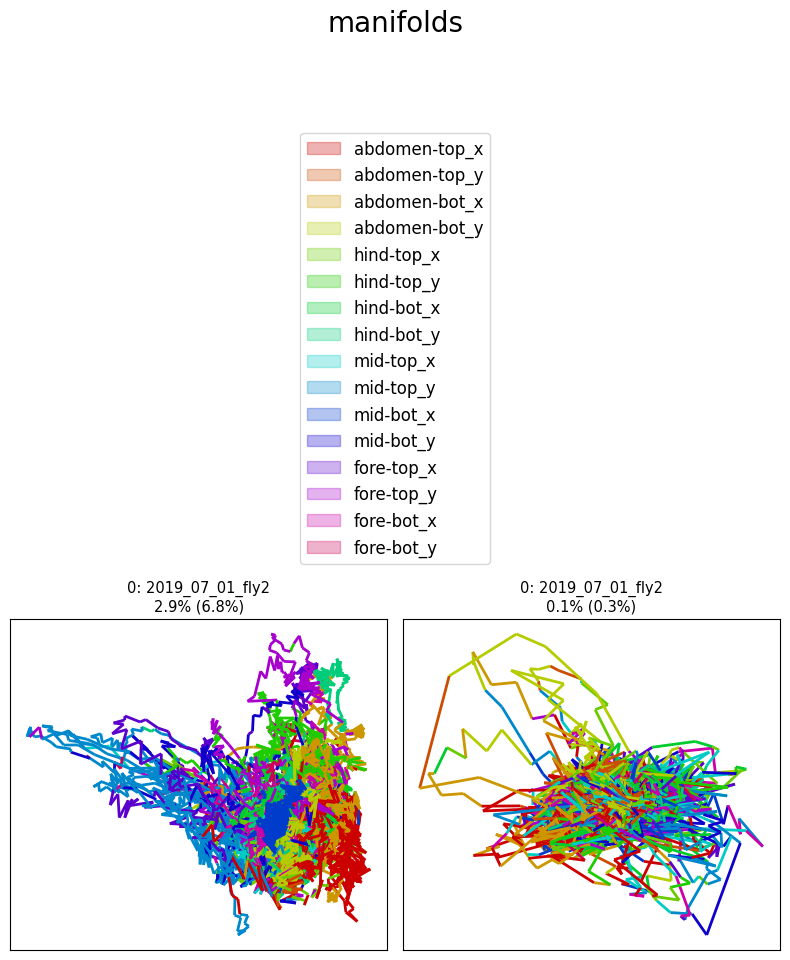

1.5% (3.6%)


In [22]:
plot_utils.plot_manifolds([f'{str(plot_id)}: {filenames[plot_idx]}'] * 2,
						  [modes_concrete[i] for i in range(2)], [markers[plot_idx] for markers in [markers_zs, markers_grad_zs]],
						  [vars_expl_con[i][:] for i in range(2)], [vars_expl_con_rs[i][:] for i in range(2)],
						  top_space=6.5)

In [23]:
traces_others = [pd.DataFrame(data=t_res.values - t_con.values, columns=t_res.columns) for t_res, t_con in zip(traces_residuals, recos_concrete)]

In [24]:
traces_all_var = np.diag(np.cov(traces[plot_idx].values, rowvar=False))
traces_res_var = np.diag(np.cov(traces_residuals[plot_idx].values, rowvar=False))
traces_man_var = traces_all_var - traces_res_var
traces_oth_var = np.diag(np.cov(traces_others[plot_idx].values, rowvar=False))
traces_con_var = traces_res_var - traces_oth_var
mco = pd.DataFrame(data=np.vstack([traces_all_var, traces_man_var, traces_res_var, traces_con_var, traces_oth_var]),
				   columns=traces[plot_idx].columns,
				   index=['a', 'm', 'r', 'c', 'o'])

traces_all_var_ratio = traces_all_var / traces_all_var
traces_res_var_ratio = traces_res_var / traces_all_var
traces_man_var_ratio = traces_man_var / traces_all_var
traces_oth_var_ratio = traces_oth_var / traces_all_var
traces_con_var_ratio = traces_con_var / traces_all_var
mco_ratio = pd.DataFrame(data=np.vstack([traces_all_var_ratio, traces_man_var_ratio, traces_res_var_ratio, traces_con_var_ratio, traces_oth_var_ratio]),
						 columns=traces[plot_idx].columns,
						 index=['a', 'm', 'r', 'c', 'o'])

In [25]:
mco_ratio_c = mco_ratio.T[['m', 'c', 'o']].sort_values(by='c', ascending=False).T
most = mco_ratio_c.loc[['c']].iloc[0]
print(most)

00_249     0.158845
00_295     0.151181
00_176     0.145633
00_365     0.135914
00_789     0.134739
             ...   
00_1220    0.002097
00_1133    0.002075
00_1210    0.001950
00_1535    0.001800
00_1157    0.001531
Name: c, Length: 1559, dtype: float64


In [26]:
cross_correls = [np.empty(()), np.empty(())]
for i in range(2):
	cross_correls[i] = np.array([
		np.corrcoef(modes_concrete[i].values[:, j], modes_concrete_b[i].values[:, j])[0, 1] for j in range(modes_concrete[i].values.shape[1])
	])

	correl_mean = np.mean(cross_correls[i])
	print(f'{i}\t: {correl_mean:.2f}')

0	: 0.78
1	: 0.30


In [27]:
print(cross_correls[0])
print(cross_correls[1])

[0.94474119 0.92750719 0.88417526 0.87519956 0.85189166 0.8315183
 0.81215084 0.80382529 0.78874514 0.7677311  0.74719839 0.72196605
 0.68827592 0.63630331 0.62008665 0.53872861]
[0.50130161 0.43980853 0.38958823 0.37729787 0.33931516 0.30603976
 0.28977924 0.28491357 0.2764144  0.26970059 0.25705504 0.25148632
 0.25085608 0.23334982 0.20291785 0.17055888]


In [28]:
loads_indices = [np.argsort(xloads_cca_con[:, 0]) for xloads_cca_con in loads_cca_con]

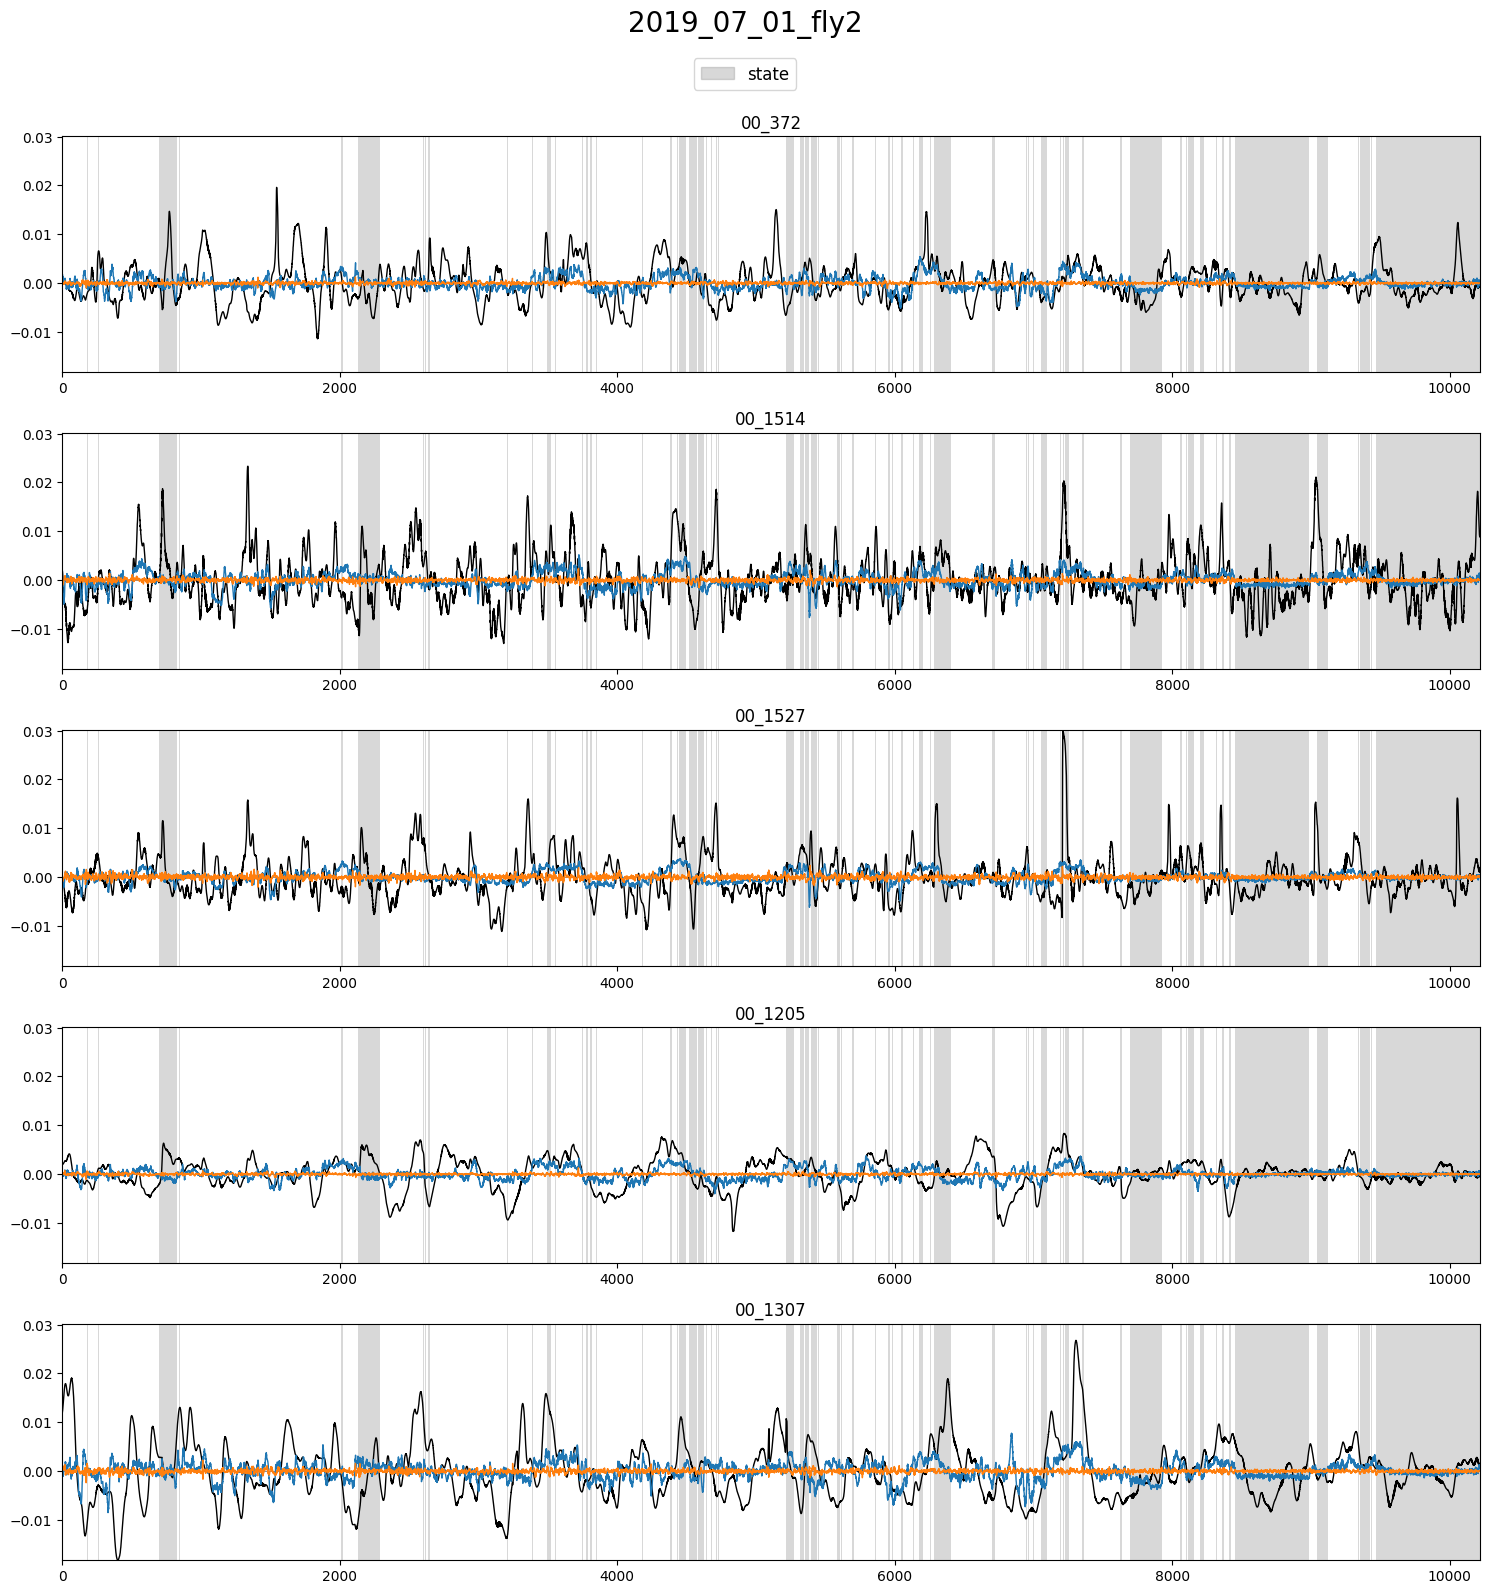

In [29]:
max = traces_residuals[plot_idx].values.shape[0]

plot_utils.plot_traces([traces_residuals[plot_idx].iloc[:max, loads_indices[0][-5:]],
					    recos_concrete[0].iloc[:max, loads_indices[0][-5:]],
					    recos_concrete[1].iloc[:max, loads_indices[0][-5:]]],
					   states[plot_idx].loc[:max, ['still']],
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)